In [14]:
import os 
from pathlib import Path
from dotenv import load_dotenv

import pandas as pd 
load_dotenv(override=True)
import numpy as np

import matplotlib.pyplot as plt

In [3]:
data_repo_path = os.getenv("DATA_REPO_PATH")
DATA_REPO_DIR = Path(data_repo_path)

data_repo_base_path = os.getenv("DATA_REPO_BASE")
DATA_REPO_BASE_DIR = Path(data_repo_base_path)

In [4]:
clubs = pd.read_csv(DATA_REPO_BASE_DIR / "2026-2027" / "teams.csv")

In [10]:
gw_club_stats = []

for i in range(1,6):
    gw_stats = pd.read_csv(DATA_REPO_DIR / f"GW{i}" / "matches.csv")

    # Total goals scored, home and away
    clubs["home_goals_scored"] = clubs["code"].map(
        gw_stats.set_index("home_team")["home_score"]
    )
    clubs["away_goals_scored"] = clubs["code"].map(
        gw_stats.set_index("away_team")["away_score"]
    )
    clubs.fillna(0, inplace=True)
    clubs["goals_scored"] = clubs["home_goals_scored"] + clubs["away_goals_scored"]

    # Total chances missed, home and away
    clubs["home_chances_missed"] = clubs["code"].map(
        gw_stats.set_index("home_team")["home_big_chances_missed"]
    )
    clubs["away_chances_missed"] = clubs["code"].map(
        gw_stats.set_index("away_team")["away_big_chances_missed"]
    )
    clubs.fillna(0, inplace=True)
    clubs["big_chances_missed"] = clubs["home_chances_missed"] + clubs["away_chances_missed"]
    
    gw_club_stats.append(clubs.copy())

gw_chances = pd.concat(
    [gw[['short_name', 'goals_scored', 'big_chances_missed' ] ] for gw in gw_club_stats],
    ignore_index=True
)

gw_chances = gw_chances.groupby("short_name").agg({
    'goals_scored':'sum',
    'big_chances_missed':'sum'
}).reset_index()
    

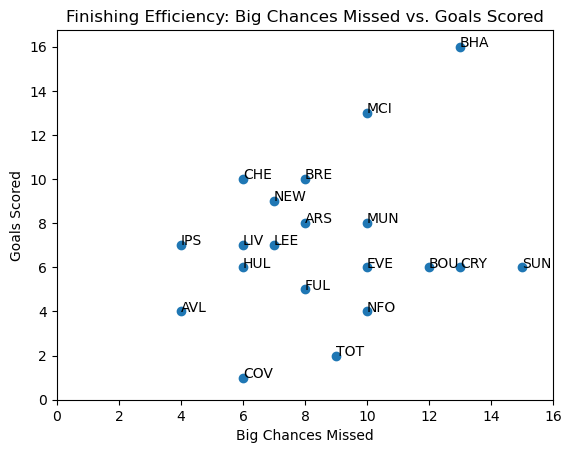

In [17]:
plt.scatter(gw_chances["big_chances_missed"], gw_chances["goals_scored"])
plt.xticks(np.arange(0, 18, 2))
plt.yticks(np.arange(0, 18, 2))
plt.title("Finishing Efficiency: Big Chances Missed vs. Goals Scored")
plt.xlabel("Big Chances Missed")
plt.ylabel("Goals Scored")

for _, row in gw_chances.iterrows():
    plt.annotate(
        row["short_name"],
        (row["big_chances_missed"], row["goals_scored"])
    )
